In [1]:
#Feature Engineerimg

In [2]:
import pandas as pd

# Sample dataset
data = {
    "Name": ["Viraj", "Mayur", "Shyam"],
    "Age": [25,25,20],
    "Gender": ["Male", "Male", "Male"],
    "Salary": [50000, 60000, 70000],
    "Joining_Date": ["2022-01-01", "2021-06-15", "2020-03-20"]
}

df = pd.DataFrame(data)

# Display dataset
df

,Name,Age,Gender,Salary,Joining_Date
0,Viraj,25,Male,50000,2022-01-01
1,Mayur,25,Male,60000,2021-06-15
2,Shyam,20,Male,70000,2020-03-20


In [3]:
# Check data types
df.dtypes

,0
Name,object
Age,int64
Gender,object
Salary,int64
Joining_Date,object


In [4]:
import pandas as pd
import numpy as np

# Sample numerical data
data = {
    "Age": [20,30,15,25,45],
    "Salary": [20000, 60000, 400000, 30000, 150000]
}

df = pd.DataFrame(data)
df

,Age,Salary
0,20,20000
1,30,60000
2,15,400000
3,25,30000
4,45,150000


In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = df.copy()
df_scaled[["Age", "Salary"]] = scaler.fit_transform(df[["Age", "Salary"]])

df_scaled

,Age,Salary
0,-0.679900,-0.790853
1,0.291386,-0.508406
2,-1.165543,1.892399
3,-0.194257,-0.720241
4,1.748315,0.127101


In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized = df.copy()
df_normalized[["Age", "Salary"]] = scaler.fit_transform(df[["Age", "Salary"]])

df_normalized

,Age,Salary
0,0.166667,0.000000
1,0.500000,0.105263
2,0.000000,1.000000
3,0.333333,0.026316
4,1.000000,0.342105


In [7]:
# Apply log transformation
df_log = df.copy()
df_log["Salary_Log"] = np.log(df_log["Salary"])

df_log

,Age,Salary,Salary_Log
0,20,20000,9.903488
1,30,60000,11.002100
2,15,400000,12.899220
3,25,30000,10.308953
4,45,150000,11.918391


In [8]:
# Create bins for Age
bins = [0, 20, 40, 100]
labels = ["Young", "Adult", "Senior"]

df["Age_Group"] = pd.cut(df["Age"], bins=bins, labels=labels)

df

,Age,Salary,Age_Group
0,20,20000,Young
1,30,60000,Adult
2,15,400000,Young
3,25,30000,Adult
4,45,150000,Senior


In [9]:
import pandas as pd

data = {
    "Name": ["ram", "shyam", "mohan", "viraj", "mayur","lakshman"],
    "Gender": ["male", "male", "male", "Male", "male","male"],
    "City": ["Mumbai", "Delhi", "Mumbai", "Pune", "Delhi","Delhi"],
    "Performance": ["Low", "Medium", "High", "Medium", "Low","High"]
}

df = pd.DataFrame(data)
df

,Name,Gender,City,Performance
0,ram,male,Mumbai,Low
1,shyam,male,Delhi,Medium
2,mohan,male,Mumbai,High
3,viraj,Male,Pune,Medium
4,mayur,male,Delhi,Low
5,lakshman,male,Delhi,High


In [10]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["Gender_Label"] = le.fit_transform(df["Gender"])
df["City_Label"] = le.fit_transform(df["City"])
df

,Name,Gender,City,Performance,Gender_Label,City_Label
0,ram,male,Mumbai,Low,1,1
1,shyam,male,Delhi,Medium,1,0
2,mohan,male,Mumbai,High,1,1
3,viraj,Male,Pune,Medium,0,2
4,mayur,male,Delhi,Low,1,0
5,lakshman,male,Delhi,High,1,0


In [11]:
# Define order
order = {"Low": 3, "Medium": 2, "High": 1}

df["Performance_Ordinal"] = df["Performance"].map(order)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal
0,ram,male,Mumbai,Low,1,1,3
1,shyam,male,Delhi,Medium,1,0,2
2,mohan,male,Mumbai,High,1,1,1
3,viraj,Male,Pune,Medium,0,2,2
4,mayur,male,Delhi,Low,1,0,3
5,lakshman,male,Delhi,High,1,0,1


In [12]:
freq = df["City"].value_counts()

df["City_Freq"] = df["City"].map(freq)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal,City_Freq
0,ram,male,Mumbai,Low,1,1,3,2
1,shyam,male,Delhi,Medium,1,0,2,3
2,mohan,male,Mumbai,High,1,1,1,2
3,viraj,Male,Pune,Medium,0,2,2,1
4,mayur,male,Delhi,Low,1,0,3,3
5,lakshman,male,Delhi,High,1,0,1,3


In [13]:
# Create a dummy target variable
df["Target"] = [0, 1, 1, 0, 1,2]

# Calculate mean target per category
target_mean = df.groupby("City")["Target"].mean()

df["City_Target_Encoded"] = df["City"].map(target_mean)
df

,Name,Gender,City,Performance,Gender_Label,City_Label,Performance_Ordinal,City_Freq,Target,City_Target_Encoded
0,ram,male,Mumbai,Low,1,1,3,2,0,0.500000
1,shyam,male,Delhi,Medium,1,0,2,3,1,1.333333
2,mohan,male,Mumbai,High,1,1,1,2,1,0.500000
3,viraj,Male,Pune,Medium,0,2,2,1,0,0.000000
4,mayur,male,Delhi,Low,1,0,3,3,1,1.333333
5,lakshman,male,Delhi,High,1,0,1,3,2,1.333333


In [14]:
import pandas as pd

data = {
    "Name": ["ram", "mayur", "lakshman"],
    "Joining_Date": ["2022-01-15", "2021-06-20", "2020-12-05"]
}

df = pd.DataFrame(data)

df.info()
# Convert to datetime
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"])

df

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Name          3 non-null      object
 1   Joining_Date  3 non-null      object
dtypes: object(2)
memory usage: 180.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Name          3 non-null      object        
 1   Joining_Date  3 non-null      datetime64[ns]
dtypes: datetime64[ns](1), object(1)
memory usage: 180.0+ bytes


In [16]:
df["Year"] = df["Joining_Date"].dt.year
df["Month"] = df["Joining_Date"].dt.month
df["Day"] = df["Joining_Date"].dt.day
df["dayname"] = df["Joining_Date"].dt.day_name()
df

,Name,Joining_Date,Year,Month,Day,dayname
0,ram,2022-01-15,2022,1,15,Saturday
1,mayur,2021-06-20,2021,6,20,Sunday
2,lakshman,2020-12-05,2020,12,5,Saturday


In [17]:
# Create sample datetime with time
df["Full_DateTime"] = pd.to_datetime([
    "2022-01-15 10:30:00",
    "2021-06-20 14:45:00",
    "2020-12-05 08:15:00"
])

df["Hour"] = df["Full_DateTime"].dt.hour
df["Minute"] = df["Full_DateTime"].dt.minute

df

,Name,Joining_Date,Year,Month,Day,dayname,Full_DateTime,Hour,Minute
0,ram,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30
1,mayur,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45
2,lakshman,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15


In [18]:
import numpy as np
#Cyclical encoding converts months into circular values so the model understands that December and January are adjacent months.
# Apply on Month
df["Month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["Month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

df

,Name,Joining_Date,Year,Month,Day,dayname,Full_DateTime,Hour,Minute,Month_sin,Month_cos
0,ram,2022-01-15,2022,1,15,Saturday,2022-01-15 10:30:00,10,30,5.000000e-01,0.866025
1,mayur,2021-06-20,2021,6,20,Sunday,2021-06-20 14:45:00,14,45,1.224647e-16,-1.000000
2,lakshman,2020-12-05,2020,12,5,Saturday,2020-12-05 08:15:00,8,15,-2.449294e-16,1.000000


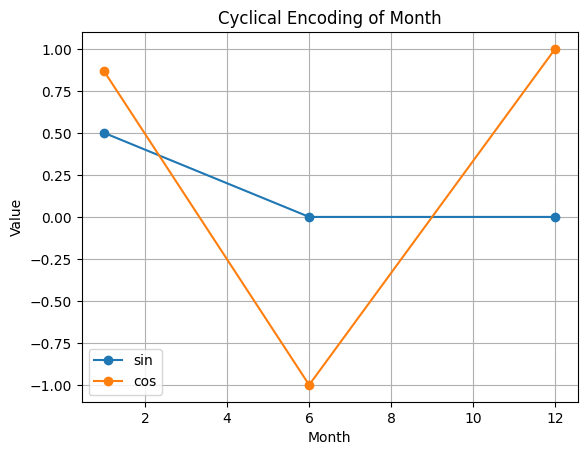

In [19]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(df["Month"], df["Month_sin"], marker='o', label="sin")
plt.plot(df["Month"], df["Month_cos"], marker='o', label="cos")

plt.xlabel("Month")
plt.ylabel("Value")
plt.title("Cyclical Encoding of Month")
plt.legend()
plt.grid()

plt.show()

In [20]:
import pandas as pd

data = {
    "Name": ["ram", "mayur", "lakshman"],
    "Price": [100, 200, 150],
    "Quantity": [2, 3, 5],
    "First_Name": ["ram", "mayur", "lakshman"],
    "Last_Name": ["joshi", "pawar", "sundar"],
    "Email": ["ram@gmail.com", "mayur@yahoo.com", "lakshman@outlook.com"]
}

df = pd.DataFrame(data)
df

,Name,Price,Quantity,First_Name,Last_Name,Email
0,ram,100,2,ram,joshi,ram@gmail.com
1,mayur,200,3,mayur,pawar,mayur@yahoo.com
2,lakshman,150,5,lakshman,sundar,lakshman@outlook.com


In [21]:
# Create Total Price
df["Total_Price"] = df["Price"] * df["Quantity"]

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price
0,ram,100,2,ram,joshi,ram@gmail.com,200
1,mayur,200,3,mayur,pawar,mayur@yahoo.com,600
2,lakshman,150,5,lakshman,sundar,lakshman@outlook.com,750


In [22]:
# Full Name
df["Full_Name"] = df["First_Name"] + " " + df["Last_Name"]

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name
0,ram,100,2,ram,joshi,ram@gmail.com,200,ram joshi
1,mayur,200,3,mayur,pawar,mayur@yahoo.com,600,mayur pawar
2,lakshman,150,5,lakshman,sundar,lakshman@outlook.com,750,lakshman sundar


In [23]:
# Extract email domain
df["Email_Domain"] = df["Email"].apply(lambda x: x.split("@")[1])

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain
0,ram,100,2,ram,joshi,ram@gmail.com,200,ram joshi,gmail.com
1,mayur,200,3,mayur,pawar,mayur@yahoo.com,600,mayur pawar,yahoo.com
2,lakshman,150,5,lakshman,sundar,lakshman@outlook.com,750,lakshman sundar,outlook.com


In [24]:
# Add sample data
df["Weight"] = [60, 70, 80]   # kg
df["Height"] = [1.6, 1.7, 1.8]  # meters

# BMI Formula
df["BMI"] = df["Weight"] / (df["Height"] ** 2)

df

,Name,Price,Quantity,First_Name,Last_Name,Email,Total_Price,Full_Name,Email_Domain,Weight,Height,BMI
0,ram,100,2,ram,joshi,ram@gmail.com,200,ram joshi,gmail.com,60,1.6,23.437500
1,mayur,200,3,mayur,pawar,mayur@yahoo.com,600,mayur pawar,yahoo.com,70,1.7,24.221453
2,lakshman,150,5,lakshman,sundar,lakshman@outlook.com,750,lakshman sundar,outlook.com,80,1.8,24.691358


In [25]:
import pandas as pd
import numpy as np

data = {
    "Age": [25, np.nan, 30, 35, np.nan],
    "Salary": [50000, 60000, np.nan, 80000, 90000],
    "City": ["Mumbai", "Delhi", None, "Pune", "Delhi"]
}

df = pd.DataFrame(data)
df

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


In [26]:
df.isnull().sum()

,0
Age,2
Salary,1
City,1


In [27]:
df2 = df.copy()
df2["Age"] = df2["Age"].fillna(df2["Age"].mean())

df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,NaN,None
3,35.0,80000.0,Pune
4,30.0,90000.0,Delhi


In [28]:
df2 = df.copy()

df2["Salary"] = df2["Salary"].fillna(df2["Salary"].median())

df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,70000.0,None
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


In [29]:
df2 = df.copy()

df2["City"] = df2["City"].fillna(df2["City"].mode()[0])

df2

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,NaN,60000.0,Delhi
2,30.0,NaN,Delhi
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


In [30]:
df_ffill = df.ffill()

df_ffill

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,25.0,60000.0,Delhi
2,30.0,60000.0,Delhi
3,35.0,80000.0,Pune
4,35.0,90000.0,Delhi


In [31]:
df_bfill = df.bfill()

df_bfill

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,80000.0,Pune
3,35.0,80000.0,Pune
4,NaN,90000.0,Delhi


In [32]:
df["Age_missing"] = df["Age"].isnull().astype(int)

df

,Age,Salary,City,Age_missing
0,25.0,50000.0,Mumbai,0
1,NaN,60000.0,Delhi,1
2,30.0,NaN,None,0
3,35.0,80000.0,Pune,0
4,NaN,90000.0,Delhi,1


In [33]:
import pandas as pd

data = {
    "Age": [25, 30, 35, 40, 45],
    "Salary": [30000, 40000, 50000, 60000, 70000],
    "Experience": [1, 3, 5, 7, 9],
    "Purchased": [0, 0, 1, 1, 1]  # Target variable
}

df = pd.DataFrame(data)
df

,Age,Salary,Experience,Purchased
0,25,30000,1,0
1,30,40000,3,0
2,35,50000,5,1
3,40,60000,7,1
4,45,70000,9,1


In [34]:
df.corr()

,Age,Salary,Experience,Purchased
Age,1.000000,1.000000,1.000000,0.866025
Salary,1.000000,1.000000,1.000000,0.866025
Experience,1.000000,1.000000,1.000000,0.866025
Purchased,0.866025,0.866025,0.866025,1.000000


In [35]:
# Correlation with target
corr_with_target = df.corr()["Purchased"]

corr_with_target

,Purchased
Age,0.866025
Salary,0.866025
Experience,0.866025
Purchased,1.000000


In [36]:
# Example: Drop a feature (if low importance)
df_selected = df.drop(columns=["Age"])  # just for demo

df_selected

,Salary,Experience,Purchased
0,30000,1,0
1,40000,3,0
2,50000,5,1
3,60000,7,1
4,70000,9,1


In [37]:
import pandas as pd

data = {
    "Salary": [30000, 35000, 40000, 45000, 50000, 1000000, 2]  # Outlier present
}

df = pd.DataFrame(data)
df

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,1000000
6,2


In [38]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_bound, upper_bound

# Detect outliers
outliers = df[(df["Salary"] < lower_bound) | (df["Salary"] > upper_bound)]

print(outliers)

    Salary
5  1000000
6        2


In [39]:
df_no_outliers = df[(df["Salary"] >= lower_bound) & (df["Salary"] <= upper_bound)]
df_no_outliers

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000


In [40]:
df_capped = df.copy()

df_capped["Salary"] = df_capped["Salary"].clip(lower_bound, upper_bound)
df_capped

,Salary
0,30000
1,35000
2,40000
3,45000
4,50000
5,70000
6,10000


In [41]:
from scipy import stats

z_scores = stats.zscore(df["Salary"])
z_scores

array([-0.41769094, -0.40292412, -0.3881573 , -0.37339047, -0.35862365,
        2.44707244, -0.50628596])

In [42]:
df_z = df[(abs(z_scores) > 2)]
df_z

,Salary
5,1000000


In [43]:
import pandas as pd
import numpy as np


data = {
    "Age": [25, np.nan, 30, 35, np.nan],
    "Salary": [50000, 60000, np.nan, 80000, 90000],
    "City": ["Mumbai", "Delhi", None, "Pune", "Delhi"]
}
df_clean = pd.DataFrame(data)


df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].mean())
df_clean["Salary"] = df_clean["Salary"].fillna(df_clean["Salary"].mean())


df_clean["City"] = df_clean["City"].fillna(df_clean["City"].mode()[0])

display(df_clean)

,Age,Salary,City
0,25.0,50000.0,Mumbai
1,30.0,60000.0,Delhi
2,30.0,70000.0,Delhi
3,35.0,80000.0,Pune
4,30.0,90000.0,Delhi


In [44]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

data_scaling = {
    "Age": [20, 30, 15, 25, 45],
    "Salary": [20000, 60000, 400000, 30000, 150000]
}
df_scaling = pd.DataFrame(data_scaling)

print("Before Scaling:")
display(df_scaling)

std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

df_scaled_result = df_scaling.copy()
df_scaled_result["Salary_Standardized"] = std_scaler.fit_transform(df_scaling[["Salary"]])
df_scaled_result["Age_Normalized"] = minmax_scaler.fit_transform(df_scaling[["Age"]])

print("After Scaling:")
display(df_scaled_result)

Before Scaling:


,Age,Salary
0,20,20000
1,30,60000
2,15,400000
3,25,30000
4,45,150000


After Scaling:


,Age,Salary,Salary_Standardized,Age_Normalized
0,20,20000,-0.790853,0.166667
1,30,60000,-0.508406,0.500000
2,15,400000,1.892399,0.000000
3,25,30000,-0.720241,0.333333
4,45,150000,0.127101,1.000000


In [45]:
from sklearn.preprocessing import LabelEncoder

data_categorical = {
    "Name": ["ram", "shyam", "mohan", "viraj", "mayur", "lakshman"],
    "Gender": ["male", "male", "male", "Male", "male", "male"],
    "City": ["Mumbai", "Delhi", "Mumbai", "Pune", "Delhi", "Delhi"]
}
df_cat = pd.DataFrame(data_categorical)

le = LabelEncoder()
df_cat["Gender_Label"] = le.fit_transform(df_cat["Gender"])

df_ohe_city = pd.get_dummies(df_cat["City"], prefix="City", dtype=int)
df_encoded = pd.concat([df_cat, df_ohe_city], axis=1)

display(df_encoded)

,Name,Gender,City,Gender_Label,City_Delhi,City_Mumbai,City_Pune
0,ram,male,Mumbai,1,0,1,0
1,shyam,male,Delhi,1,1,0,0
2,mohan,male,Mumbai,1,0,1,0
3,viraj,Male,Pune,0,0,0,1
4,mayur,male,Delhi,1,1,0,0
5,lakshman,male,Delhi,1,1,0,0


In [46]:
data_spending = {
    "Salary": [50000, 60000, 70000],
    "Purchase_Amount": [5000, 12000, 8000]
}
df_spend = pd.DataFrame(data_spending)
df_spend["Total_Spending"] = df_spend["Salary"] + df_spend["Purchase_Amount"]

display(df_spend)

,Salary,Purchase_Amount,Total_Spending
0,50000,5000,55000
1,60000,12000,72000
2,70000,8000,78000


In [47]:
data_date = {
    "Name": ["ram", "mayur", "lakshman"],
    "Joining_Date": ["2022-01-15", "2021-06-20", "2020-12-05"]
}
df_date = pd.DataFrame(data_date)
df_date["Joining_Date"] = pd.to_datetime(df_date["Joining_Date"])

df_date["Year"] = df_date["Joining_Date"].dt.year
df_date["Month"] = df_date["Joining_Date"].dt.month
df_date["Day"] = df_date["Joining_Date"].dt.day
df_date["Weekday"] = df_date["Joining_Date"].dt.day_name()

display(df_date)

,Name,Joining_Date,Year,Month,Day,Weekday
0,ram,2022-01-15,2022,1,15,Saturday
1,mayur,2021-06-20,2021,6,20,Sunday
2,lakshman,2020-12-05,2020,12,5,Saturday


In [48]:
data_binning = {
    "Age": [20, 30, 15, 25, 45, 50, 12, 60]
}
df_bin = pd.DataFrame(data_binning)

bins = [-1, 25, 45, np.inf]
labels = ["Young", "Adult", "Senior"]

df_bin["Age_Group"] = pd.cut(df_bin["Age"], bins=bins, labels=labels)
display(df_bin)

,Age,Age_Group
0,20,Young
1,30,Adult
2,15,Young
3,25,Young
4,45,Adult
5,50,Senior
6,12,Young
7,60,Senior


In [49]:
data_outliers = {
    "Salary": [30000, 35000, 40000, 45000, 50000, 1000000, 2]
}
df_outliers = pd.DataFrame(data_outliers)

Q1 = df_outliers["Salary"].quantile(0.25)
Q3 = df_outliers["Salary"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_rows = df_outliers[(df_outliers["Salary"] < lower_bound) | (df_outliers["Salary"] > upper_bound)]
display(outlier_rows)

,Salary
5,1000000
6,2


In [50]:
data_interaction = {
    "Salary": [30000, 40000, 50000, 60000, 70000],
    "Experience": [1, 3, 5, 7, 9]
}
df_inter = pd.DataFrame(data_interaction)
df_inter["Experience_Salary"] = df_inter["Experience"] * df_inter["Salary"]

display(df_inter)

,Salary,Experience,Experience_Salary
0,30000,1,30000
1,40000,3,120000
2,50000,5,250000
3,60000,7,420000
4,70000,9,630000


In [51]:
data_selection = {
    "Age": [25, 30, 35, 40, 45],
    "Salary": [30000, 40000, 50000, 60000, 70000],
    "Experience": [1, 3, 5, 7, 9],
    "Purchase_Amount": [100, 150, 400, 600, 500],
    "Extra_Feature": [5, 5, 5, 5, 5]
}
df_sel = pd.DataFrame(data_selection)

correlations = df_sel.corr()["Purchase_Amount"].drop("Purchase_Amount")
print("Correlations with Purchase_Amount:")
print(correlations)

least_important = correlations.abs().idxmin()
print(f"\nDropping the least correlated feature: {least_important}")

df_final_selection = df_sel.drop(columns=[least_important])
display(df_final_selection)

Correlations with Purchase_Amount:
Age              0.906845
Salary           0.906845
Experience       0.906845
Extra_Feature         NaN
Name: Purchase_Amount, dtype: float64

Dropping the least correlated feature: Age


,Salary,Experience,Purchase_Amount,Extra_Feature
0,30000,1,100,5
1,40000,3,150,5
2,50000,5,400,5
3,60000,7,600,5
4,70000,9,500,5
